
### SDG 8: Decent Work and Economic Growth

Data Mining and Visualization  
**Dataset:** https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce



## Objective

This notebook analyzes Brazil's e-commerce ecosystem using the Olist dataset, which covers ~100,000 orders placed between 2016–2018. The analysis is framed around **SDG 8 (Decent Work and Economic Growth)**, which promotes sustained economic growth, productive employment, and access to financial services.

E-commerce directly contributes to SDG 8 by enabling small businesses (sellers) to reach customers nationally, creating jobs in logistics and tech, and expanding economic participation in underserved regions.


## Research Questions

1. **Does delivery performance affect customer satisfaction?** (Insight 1: Delivery Delay vs Review Score)
2. **Which state experience late deliveries?** (Insight 2: Geographic Distribution of Late Deliveries)
3. **Which Product Categories Retain Customers Best??** (Insight 3: Repeat Buyers)
4. **How has e-commerce grown over time, and when do Brazilians shop?** (Insight 4: Order Trends)

In [2]:
import pandas as pd

In [3]:
DATA_DIR = '../data/raw/'  # put the 9 Kaggle CSVs here

customer = pd.read_csv(DATA_DIR + 'olist_customers_dataset.csv')
geolocation = pd.read_csv(DATA_DIR + 'olist_geolocation_dataset.csv')
order_items = pd.read_csv(DATA_DIR + 'olist_order_items_dataset.csv')
order_payments = pd.read_csv(DATA_DIR + 'olist_order_payments_dataset.csv')
order_reviews = pd.read_csv(DATA_DIR + 'olist_order_reviews_dataset.csv')
orders = pd.read_csv(DATA_DIR + 'olist_orders_dataset.csv')
products = pd.read_csv(DATA_DIR + 'olist_products_dataset.csv')
sellers = pd.read_csv(DATA_DIR + 'olist_sellers_dataset.csv')
categories = pd.read_csv(DATA_DIR + 'product_category_name_translation.csv')

In [4]:
# Collections for each dataset
datasets = [customer, geolocation, orders, order_items, order_payments,
            order_reviews, products, sellers]
names = ['olist_customer', 'olist_geolocation', 'olist_orders', 'olist_order_items', 'olist_order_payments',
         'olist_order_reviews', 'olist_products', 'olist_sellers']

# Creating a DataFrame with useful information about all datasets
data_info = pd.DataFrame({})
data_info['dataset'] = names
data_info['n_rows'] = [df.shape[0] for df in datasets]
data_info['n_cols'] = [df.shape[1] for df in datasets]
data_info['null_amount'] = [df.isnull().sum().sum() for df in datasets]
data_info['qty_null_columns'] = [len([col for col, null in df.isnull().sum().items() if null > 0]) for df in datasets]
data_info['null_columns'] = [', '.join([col for col, null in df.isnull().sum().items() if null > 0]) for df in datasets]

data_info

,dataset,n_rows,n_cols,null_amount,qty_null_columns,null_columns
0,olist_customer,99441,5,0,0,
1,olist_geolocation,1000163,5,0,0,
2,olist_orders,99441,8,4908,3,"order_approved_at, order_delivered_carrier_dat..."
3,olist_order_items,112650,7,0,0,
4,olist_order_payments,103886,5,0,0,
5,olist_order_reviews,99224,7,145903,2,"review_comment_title, review_comment_message"
6,olist_products,32951,9,2448,8,"product_category_name, product_name_lenght, pr..."
7,olist_sellers,3095,4,0,0,


In [5]:
def data_overview(df):
    return pd.DataFrame({
        "feature": df.columns,
        "qtd_null": df.isnull().sum().values,
        "percent_null": (df.isnull().sum() / len(df) * 100).values,
        "dtype": df.dtypes.astype(str).values,
        "qtd_cat": [df[col].nunique() for col in df.columns]
    })

df_overview = pd.DataFrame()

for name, df in zip(names, datasets):
    temp = data_overview(df)
    temp["dataset_name"] = name

    df_overview = pd.concat(
        [df_overview, temp],
        ignore_index=True
    )

df_overview = df_overview[
    ["dataset_name", "feature", "qtd_null", "percent_null", "dtype", "qtd_cat"]
]

df_overview

,dataset_name,feature,qtd_null,percent_null,dtype,qtd_cat
0,olist_customer,customer_id,0,0.000000,object,99441
1,olist_customer,customer_unique_id,0,0.000000,object,96096
2,olist_customer,customer_zip_code_prefix,0,0.000000,int64,14994
3,olist_customer,customer_city,0,0.000000,object,4119
4,olist_customer,customer_state,0,0.000000,object,27
5,olist_geolocation,geolocation_zip_code_prefix,0,0.000000,int64,19015
6,olist_geolocation,geolocation_lat,0,0.000000,float64,717360
7,olist_geolocation,geolocation_lng,0,0.000000,float64,717613
8,olist_geolocation,geolocation_city,0,0.000000,object,8011
9,olist_geolocation,geolocation_state,0,0.000000,object,27


## We can now use the DataFrame above wherever we want to do data analysis. The main information about each column for each one of the datasets available.

In [6]:
customer.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
# does  delivery time affect the review score?
# merge order_items and order_reviews on order_id


In [8]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [9]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

In [11]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


## Insight 1 : Does Delivery Delay Affect Customer Satisfaction? <a id='2'></a>

**Question:** Do late deliveries lead to lower review scores?

We compute delivery_delay as the difference in days between the actual delivery date and the estimated delivery date. A negative value means the order arrived **early**; a positive value means it arrived **late**.

In [12]:
# dataframe
df = orders.copy()
df = df.merge(order_reviews, on='order_id', how='inner')
df = df.merge(customer, on='customer_id', how='inner')

In [13]:
df["order_delivered_customer_date"] = pd.to_datetime(df["order_delivered_customer_date"])
df["order_estimated_delivery_date"] = pd.to_datetime(df["order_estimated_delivery_date"])

df["delivery_delay"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.days

In [14]:
df['delivery_delay']

0        -8.0
1        -6.0
2       -18.0
3       -13.0
4       -10.0
         ... 
99219   -11.0
99220    -2.0
99221    -6.0
99222   -21.0
99223   -18.0
Name: delivery_delay, Length: 99224, dtype: float64

In [15]:
df['delay_group'] = pd.cut(
    df['delivery_delay'],
    bins=[-100, 0, 5, 10, 100],
    labels=['Early', '0–5 days late', '5–10 days late', '10+ days late']
)

df['is_late'] = df['delivery_delay'] > 0

print(f"Total orders analysed: {len(df):,}")
print(f"Late deliveries: {df['is_late'].sum():,} ({df['is_late'].mean()*100:.1f}%)")

Total orders analysed: 99,224
Late deliveries: 6,410 (6.5%)


Text(0.5, 1.0, 'Delivery Delay vs Review Score')

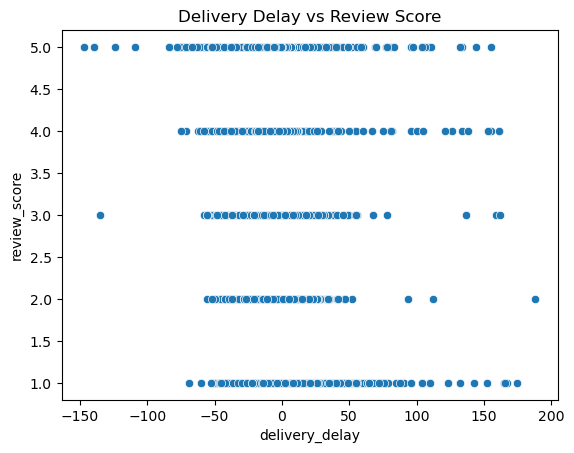

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x='delivery_delay', y='review_score', data=df)
plt.title('Delivery Delay vs Review Score')

In [17]:
df.groupby("review_score")["delivery_delay"].mean()

review_score
1    -4.060580
2    -8.634818
3   -10.774052
4   -12.380840
5   -13.388153
Name: delivery_delay, dtype: float64

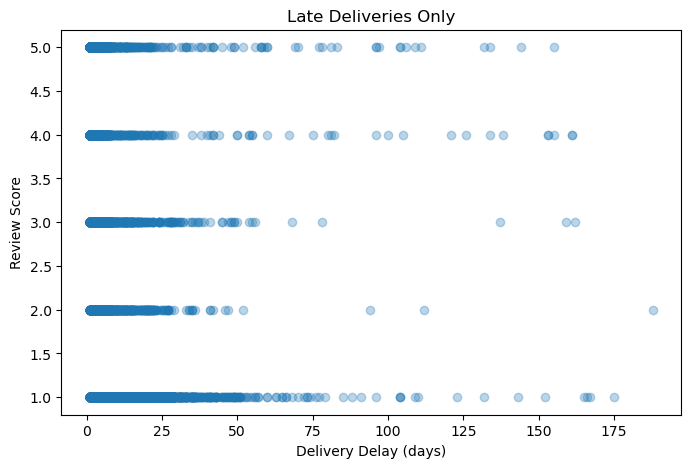

In [18]:
late_df = df[df["delivery_delay"] > 0]
plt.figure(figsize=(8,5))
plt.scatter(late_df["delivery_delay"], late_df["review_score"], alpha=0.3)
plt.xlabel("Delivery Delay (days)")
plt.ylabel("Review Score")
plt.title("Late Deliveries Only")
plt.show()

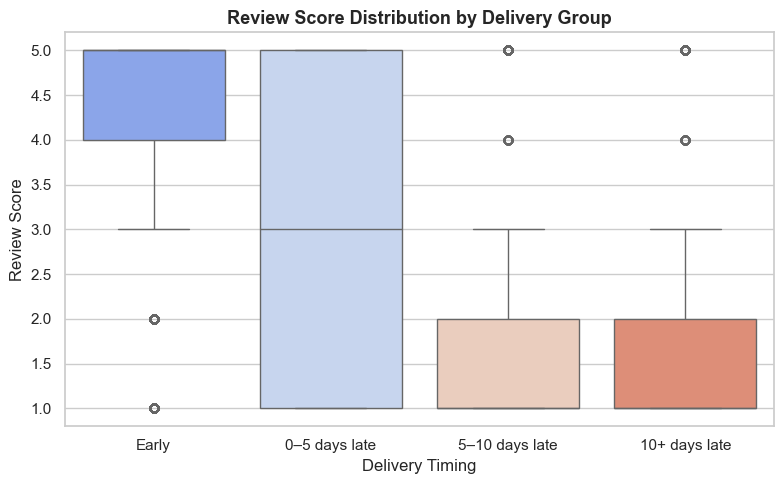

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')

delay_order = ['Early', '0–5 days late', '5–10 days late', '10+ days late']

plt.figure(figsize=(8,5))

sns.boxplot(x='delay_group', y='review_score', data=df,
            order=delay_order, hue='delay_group', palette='coolwarm', legend=False)

plt.title('Review Score Distribution by Delivery Group', fontsize=13, fontweight='bold')
plt.xlabel('Delivery Timing')
plt.ylabel('Review Score')

plt.tight_layout()
plt.show()

In [20]:
early = df[df["delivery_delay"] < 0]["review_score"].mean()
on_time = df[df["delivery_delay"] == 0]["review_score"].mean()
late = df[df["delivery_delay"] > 0]["review_score"].mean()

print(f"Early (<0): {early:.2f}")
print(f"On-time (=0): {on_time:.2f}")
print(f"Late (>0): {late:.2f}")

Early (<0): 4.29
On-time (=0): 4.03
Late (>0): 2.27


In [21]:
df["delay_bin"] = pd.cut(df["delivery_delay"], bins=[-100, -10, 0, 10, 30, 60, 200])

df.groupby("delay_bin")["review_score"].mean()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12380\188323664.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("delay_bin")["review_score"].mean()


delay_bin
(-100, -10]    4.322717
(-10, 0]       4.217284
(0, 10]        2.531915
(10, 30]       1.645785
(30, 60]       1.832031
(60, 200]      2.813333
Name: review_score, dtype: float64

In [22]:
df["is_late"] = df["delivery_delay"] > 0

print("average review score for late deliveries:")
df.groupby("is_late")["review_score"].mean()

average review score for late deliveries:


is_late
False    4.211789
True     2.271139
Name: review_score, dtype: float64

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12380\775008828.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('delay_group')['review_score']


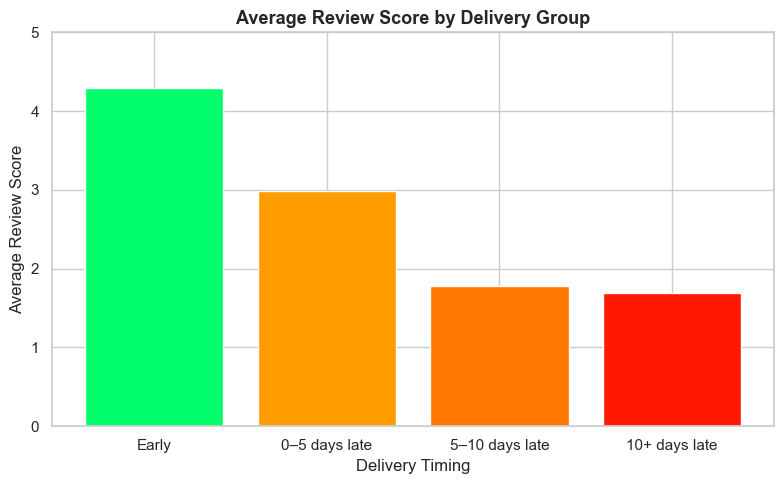

In [23]:
mean_scores = (
    df.groupby('delay_group')['review_score']
      .mean()
      .reindex(delay_order)
)

colors = ["#00ff6a", "#ff9d00", "#ff7700", "#ff1900"]

plt.figure(figsize=(8,5))

bars = plt.bar(mean_scores.index,mean_scores.values,color=colors)

plt.title('Average Review Score by Delivery Group', fontsize=13, fontweight='bold')
plt.xlabel('Delivery Timing')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

**Interpretation:**  
Delivery timing has a dramatic effect on customer satisfaction. Orders delivered **early** receive an average score of **4.29**, while orders that are **10+ days late** drop to just **1.69** : a 2.6-point gap on a 5-point scale. More than **53% of late-delivery reviews** give a score of 1 (the minimum). This confirms that logistics efficiency is the single strongest driver of customer satisfaction in this dataset.



## Insight 2 : Geographic Distribution of Late Deliveries

**Question:** Are late deliveries concentrated in specific Brazilian states? Which states have the worst logistics performance?

This directly relates to SDG 8's goal of reducing regional economic inequality. States with worse delivery performance may see slower e-commerce adoption.

In [24]:
# Build state-level delivery performance table
df_loc = orders.merge(customer, on='customer_id')
df_loc['order_delivered_customer_date'] = pd.to_datetime(df_loc['order_delivered_customer_date'])
df_loc['order_estimated_delivery_date'] = pd.to_datetime(df_loc['order_estimated_delivery_date'])
df_loc['delivery_delay'] = (
    df_loc['order_delivered_customer_date'] - df_loc['order_estimated_delivery_date']
).dt.days
df_loc['is_late'] = (df_loc['delivery_delay'] > 0).astype(int)

state_stats = df_loc.groupby('customer_state').agg(
    mean_delay = ('delivery_delay', 'mean'),
    late_rate = ('is_late', 'mean'),
    order_count = ('order_id', 'count')
).query('order_count >= 100').sort_values('late_rate', ascending=False)

state_stats['late_rate_pct'] = state_stats['late_rate'] * 100
print(state_stats[['late_rate_pct', 'mean_delay', 'order_count']].round(2).to_string())

                late_rate_pct  mean_delay  order_count
customer_state                                        
AL                      20.58       -8.71          413
MA                      16.73       -9.57          747
SE                      14.57      -10.02          350
PI                      13.33      -11.31          495
CE                      13.17      -10.80         1336
BA                      11.72      -10.79         3380
RJ                      11.63      -11.77        12852
PA                      10.87      -14.07          975
ES                      10.53      -10.50         2033
PB                      10.07      -13.26          536
TO                       9.64      -12.13          280
MS                       9.51      -11.05          715
PE                       9.26      -13.29         1652
RN                       9.07      -13.65          485
SC                       8.00      -11.51         3637
GO                       6.34      -12.19         2020
RS        

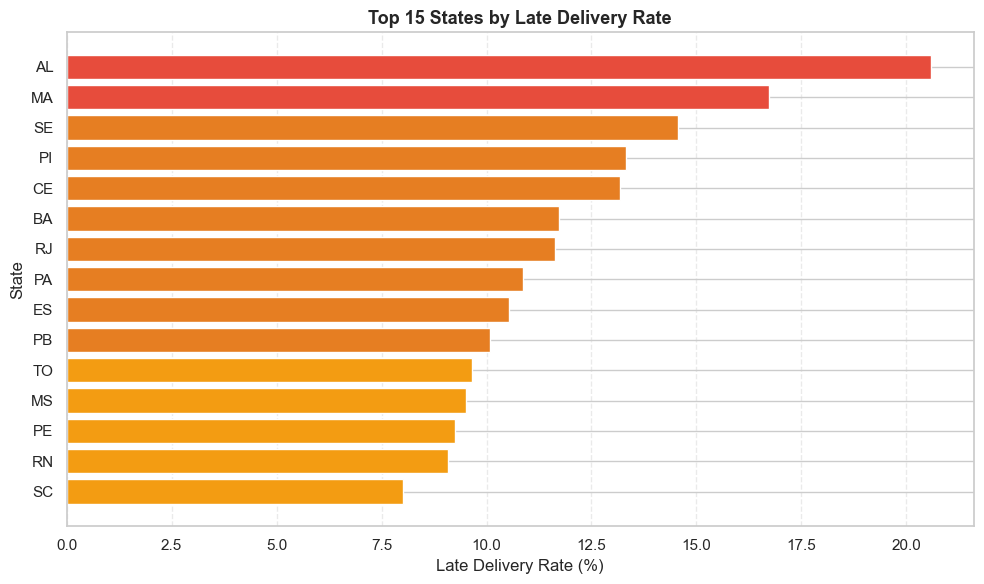

In [25]:
plt.figure(figsize=(10, 6))

top_states = state_stats.head(15)

colors_state = [
    '#e74c3c' if r > 0.15
    else '#e67e22' if r > 0.10
    else '#f39c12'
    for r in top_states['late_rate']
]

plt.barh(top_states.index[::-1],top_states['late_rate_pct'][::-1],color=colors_state[::-1],edgecolor='white')

plt.title('Top 15 States by Late Delivery Rate',fontsize=13,fontweight='bold')

plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('State')

plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

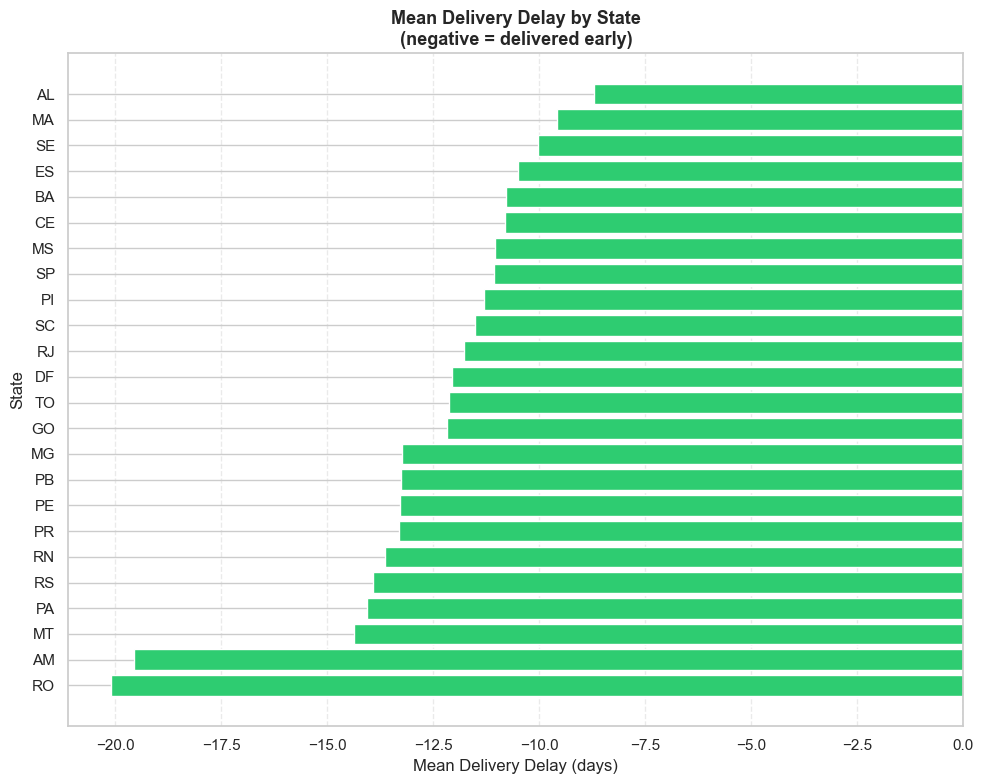

In [26]:
plt.figure(figsize=(10, 8))

all_states = state_stats.sort_values(
    'mean_delay',
    ascending=True
)

bar_colors = [
    '#e74c3c' if v > 0
    else '#2ecc71'
    for v in all_states['mean_delay']
]

plt.barh(all_states.index,all_states['mean_delay'],color=bar_colors,edgecolor='white')

plt.axvline(0,color='black',linewidth=0.8,linestyle='--')

plt.title('Mean Delivery Delay by State\n(negative = delivered early)',fontsize=13,fontweight='bold')

plt.xlabel('Mean Delivery Delay (days)')
plt.ylabel('State')

plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Interpretation:**  
States in **Brazil's Northeast region** including AL (Alagoas), MA (Maranhão), SE (Sergipe), PI (Piauí), and CE (Ceará) consistently show the highest late delivery rates, with some exceeding 20%. By contrast, northern states like **AM (Amazonas) and RO (Rondônia)** paradoxically show very low late rates despite being geographically remote, likely because estimated delivery times are already set longer for those regions.

The Southeast (SP, MG, PR) performs best in absolute terms, benefiting from the concentration of distribution infrastructure around São Paulo.

**SDG 8 implication:** Logistics inequality between regions reflects and reinforces economic inequality. Targeted investment in last-mile delivery infrastructure in the Northeast could reduce this gap and expand equitable digital economic participation.


## Insight 3 : Which Product Categories Retain Customers Best?

**Question:** Which product categories are associated with higher repeat purchase rates?

A customer is flagged as a **repeat buyer** if they placed more than one order (using customer_unique_id). We then link those buyers to their purchased product categories.

In [29]:
orders_cust = orders.merge(customer, on="customer_id")

In [30]:
customer_orders = orders_cust.groupby("customer_unique_id")["order_id"].nunique()

repeat_flag = (customer_orders > 1).astype(int).reset_index()
repeat_flag.columns = ["customer_unique_id", "repeat_flag"]

In [31]:
repeat_flag["repeat_flag"].value_counts()

repeat_flag
0    93099
1     2997
Name: count, dtype: int64

In [32]:
# Link to product categories
orders_cust = orders_cust.merge(repeat_flag, on='customer_unique_id')
df_cat = orders_cust.merge(order_items, on='order_id')
df_cat = df_cat.merge(products[['product_id','product_category_name']], on='product_id')
df_cat = df_cat.merge(categories, on='product_category_name', how='left')

# Use English name where available
df_cat['category_en'] = df_cat['product_category_name_english'].fillna(df_cat['product_category_name'])

# Repeat rate per category (minimum 200 orders)
cat_repeat = df_cat.groupby('category_en').agg(
    repeat_rate=('repeat_flag', 'mean'),
    order_count=('order_id', 'count')
).query('order_count >= 200').sort_values('repeat_rate', ascending=False)

print(f"\nCategories analysed: {len(cat_repeat)}")


Categories analysed: 46


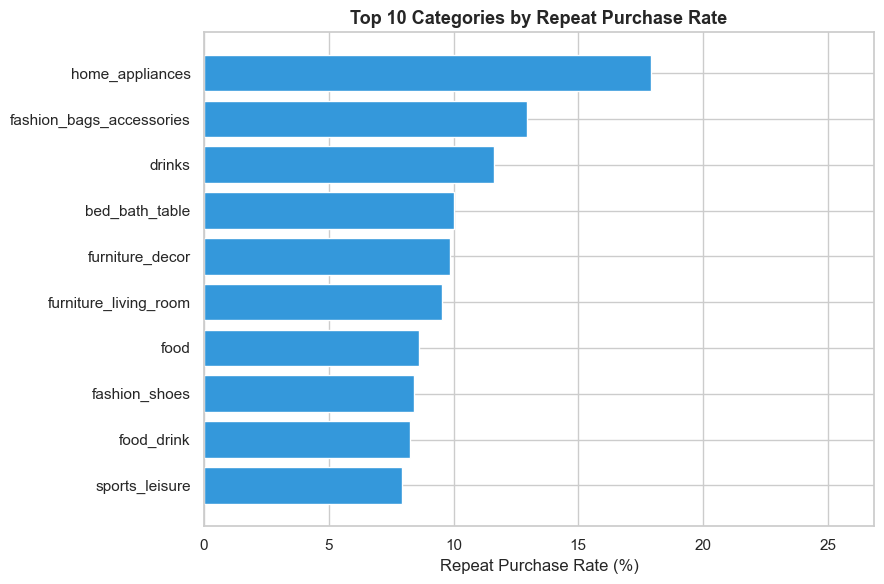

In [33]:
plt.figure(figsize=(9,6))

top10 = cat_repeat.head(10)

plt.barh(top10.index[::-1],top10['repeat_rate'][::-1] * 100,color='#3498db')

plt.title('Top 10 Categories by Repeat Purchase Rate',fontsize=13,fontweight='bold')

plt.xlabel('Repeat Purchase Rate (%)')

plt.xlim(0, top10['repeat_rate'].max() * 100 * 1.5)

plt.tight_layout()
plt.show()

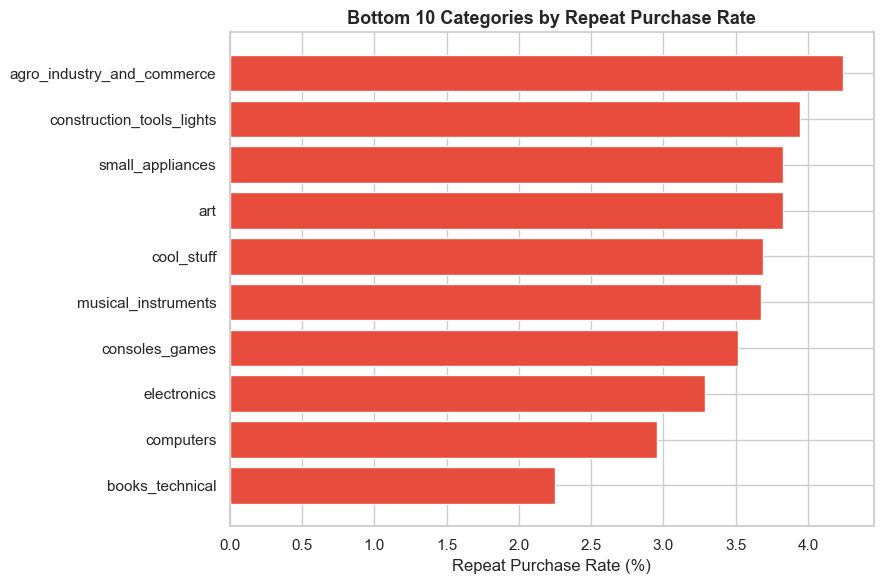

In [34]:
plt.figure(figsize=(9,6))

bot10 = cat_repeat.tail(10)

plt.barh(
    bot10.index[::-1],
    bot10['repeat_rate'][::-1] * 100,
    color='#e74c3c',
    edgecolor='white'
)

plt.title(
    'Bottom 10 Categories by Repeat Purchase Rate',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Repeat Purchase Rate (%)')

plt.tight_layout()
plt.show()

**Interpretation:**  
Product categories exhibit substantially different repeat purchase patterns. Home appliances show the highest repeat purchase rate (approximately 18%), followed by fashion accessories and drinks. In contrast, books, computers, and electronics display much lower repeat purchase rates, generally below 4%.

This suggests that customer loyalty and purchasing behavior are highly category-dependent. Categories associated with consumable products or complementary purchases tend to encourage repeat transactions, while durable goods and infrequently purchased items naturally generate fewer repeat orders.

**SDG 8 implication:** Sellers in high-repeat categories benefit from more sustainable revenue streams. Supporting these sellers with better platform tools and logistics pricing can deepen economic growth within the digital marketplace.


## Insight 4 : Order Volume Trends Over Time

**Question:** Is Brazilian e-commerce growing? When do customers tend to shop : by month, day of week, and time of day?

In [35]:
# Parse timestamps and extract time attributes
orders_time = orders.copy()
orders_time['order_purchase_timestamp'] = pd.to_datetime(orders_time['order_purchase_timestamp'])
orders_time['year_month'] = orders_time['order_purchase_timestamp'].dt.to_period('M')
orders_time['day_of_week'] = orders_time['order_purchase_timestamp'].dt.day_name()
orders_time['hour'] = orders_time['order_purchase_timestamp'].dt.hour

In [36]:
# Map hours to time-of-day buckets
def time_of_day(h):
    if 0 <= h < 6:   return 'Dawn (0–6)'
    elif 6 <= h < 12: return 'Morning (6–12)'
    elif 12 <= h < 18: return 'Afternoon (12–18)'
    else:             return 'Night (18–24)'

orders_time['time_of_day'] = orders_time['hour'].apply(time_of_day)

In [37]:
# Monthly order counts
# Filter out months with fewer than 50 orders (launch noise + data gaps)
monthly = orders_time.groupby('year_month')['order_id'].count()
monthly = monthly[monthly.index.astype(str) < '2018-09']  # remove incomplete month
monthly = monthly[monthly.values >= 50]  # remove launch noise
print(monthly.head())

year_month
2016-10     324
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
Freq: M, Name: order_id, dtype: int64


In [38]:
# Day of week counts
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = orders_time['day_of_week'].value_counts().reindex(dow_order)
print(dow)

day_of_week
Monday       16196
Tuesday      15963
Wednesday    15552
Thursday     14761
Friday       14122
Saturday     10887
Sunday       11960
Name: count, dtype: int64


In [39]:
# Time of day counts
tod_order = ['Dawn (0–6)', 'Morning (6–12)', 'Afternoon (12–18)', 'Night (18–24)']
tod = orders_time['time_of_day'].value_counts().reindex(tod_order)
print(tod)

time_of_day
Dawn (0–6)            4740
Morning (6–12)       22240
Afternoon (12–18)    38361
Night (18–24)        34100
Name: count, dtype: int64


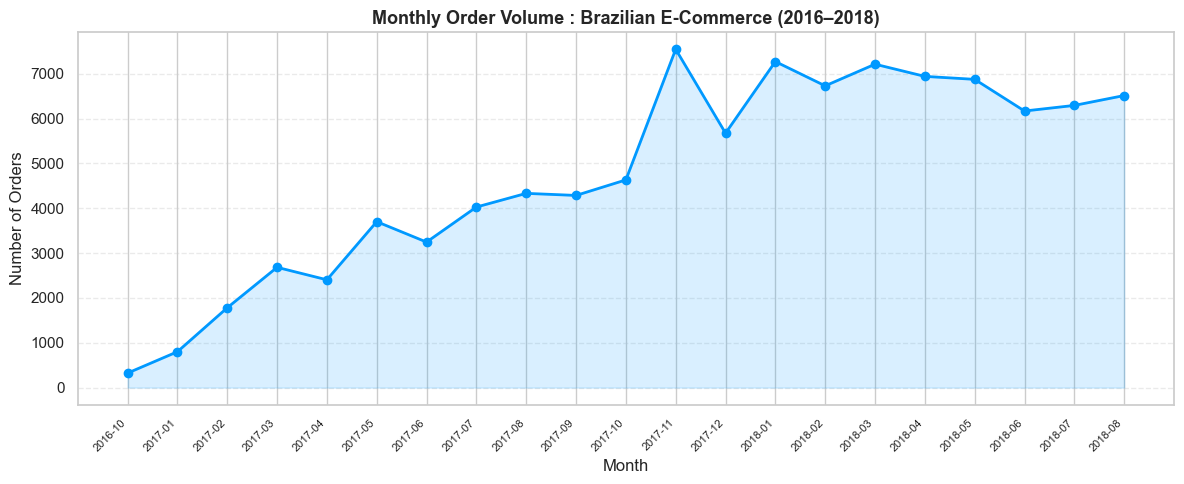

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(monthly.index.astype(str),monthly.values,marker='o',color="#0099ff",linewidth=2)

plt.fill_between(range(len(monthly)),monthly.values,alpha=0.15,color="#0099ff")

plt.xticks(range(len(monthly)),monthly.index.astype(str),rotation=45,ha='right',fontsize=8)

plt.title('Monthly Order Volume : Brazilian E-Commerce (2016–2018)',fontsize=13,fontweight='bold')

plt.ylabel('Number of Orders')
plt.xlabel('Month')

plt.grid(True, axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

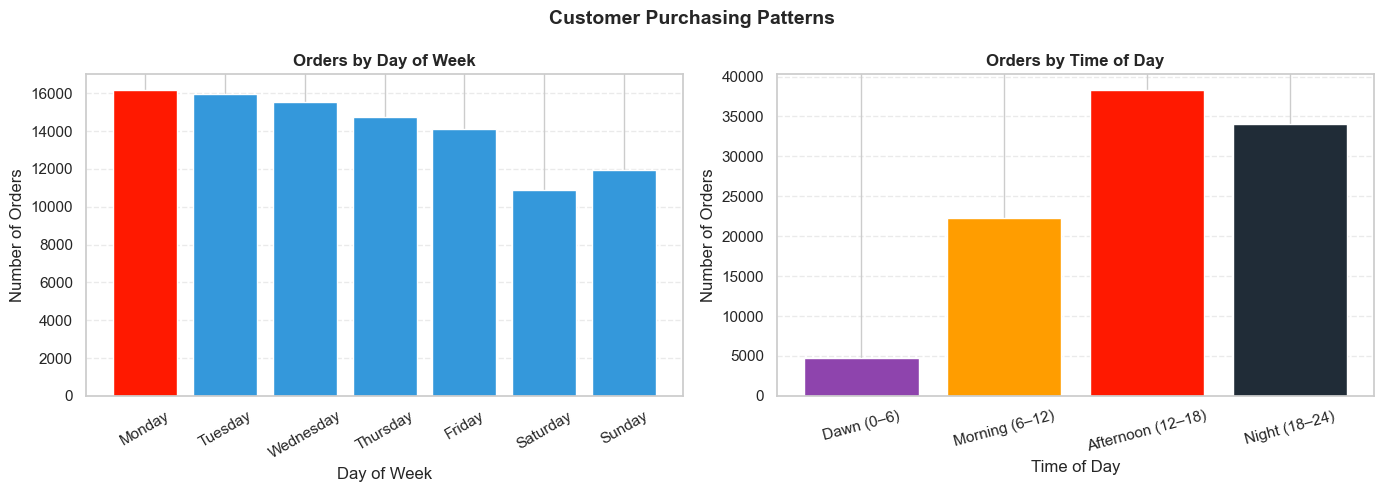

In [41]:
plt.figure(figsize=(14, 5))

# Left: Day of Week
plt.subplot(1, 2, 1)

colors_dow = [
    "#ff1900" if d == 'Monday'
    else '#3498db'
    for d in dow_order
]

plt.bar(dow_order,dow.values,color=colors_dow,edgecolor='white')

plt.title('Orders by Day of Week',fontsize=12,fontweight='bold')

plt.ylabel('Number of Orders')
plt.xlabel('Day of Week')
plt.xticks(rotation=30)
plt.grid(True, axis='y', linestyle='--', alpha=0.4)

# Right: Time of Day
plt.subplot(1, 2, 2)

colors_tod = ['#8e44ad', "#ff9d00", "#ff1900", "#202c37"]

plt.bar(tod_order,tod.values,color=colors_tod,edgecolor='white')

plt.title('Orders by Time of Day',fontsize=12,fontweight='bold')

plt.ylabel('Number of Orders')
plt.xlabel('Time of Day')
plt.xticks(rotation=15)
plt.grid(True, axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Customer Purchasing Patterns',fontsize=14,fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretation:**  
Brazilian e-commerce shows a clear **upward growth trend** from 2016 to mid-2018, with order volumes roughly tripling over that period. There is visible **seasonality** peaks around November (Black Friday) and January (post-holiday). 

**Monday** is the most popular shopping day, suggesting customers browse and buy at the start of the work week. **Afternoons (12–18h)** are the busiest period, with a secondary peak in the **night (18–24h)** consistent with consumers shopping during lunch breaks and after work.

**SDG 8 implication:** The consistent growth trend demonstrates that digital commerce is becoming an increasingly important economic channel in Brazil. Peak periods represent revenue opportunities for sellers and jobs for the logistics ecosystem that supports them.

## Insight 5 : Payment Type Analysis 

**Question:** How do Brazilian e-commerce customers prefer to pay? Has payment behavior changed over time?

Understanding payment preferences is key to ensuring financial inclusion (SDG 8.10 — access to banking and financial services).

In [42]:
# Merge payments with order timestamps
pay = order_payments.merge(
    orders[['order_id','order_purchase_timestamp']], on='order_id'
)
pay['order_purchase_timestamp'] = pd.to_datetime(pay['order_purchase_timestamp'])
pay['year_month'] = pay['order_purchase_timestamp'].dt.to_period('M')

# Monthly payment type breakdown
pay_monthly = pay.groupby(['year_month', 'payment_type'])['order_id'].count().unstack(fill_value=0)
pay_monthly = pay_monthly[pay_monthly.index.astype(str) < '2018-09']

# Overall payment type distribution
pay_dist = pay['payment_type'].value_counts()

# Installment distribution (credit card only)
cc = pay[pay['payment_type'] == 'credit_card']
installments = cc['payment_installments'].value_counts().sort_index().head(12)

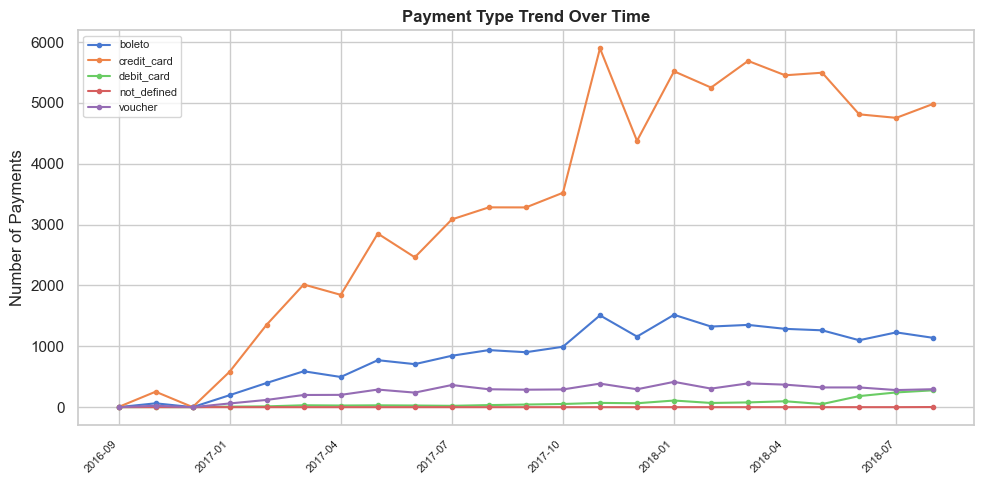

In [ ]:
plt.figure(figsize=(10, 5))

for col in pay_monthly.columns:
    plt.plot(
        range(len(pay_monthly)),
        pay_monthly[col],
        marker='o',
        markersize=3,
        linewidth=1.5,
        label=col
    )

plt.xticks(range(0, len(pay_monthly), 3),pay_monthly.index.astype(str)[::3],rotation=45,ha='right',fontsize=8)

plt.title('Payment Type Trend Over Time',fontsize=12,fontweight='bold')
plt.ylabel('Number of Payments')
plt.legend(fontsize=8)

plt.tight_layout()
plt.show()

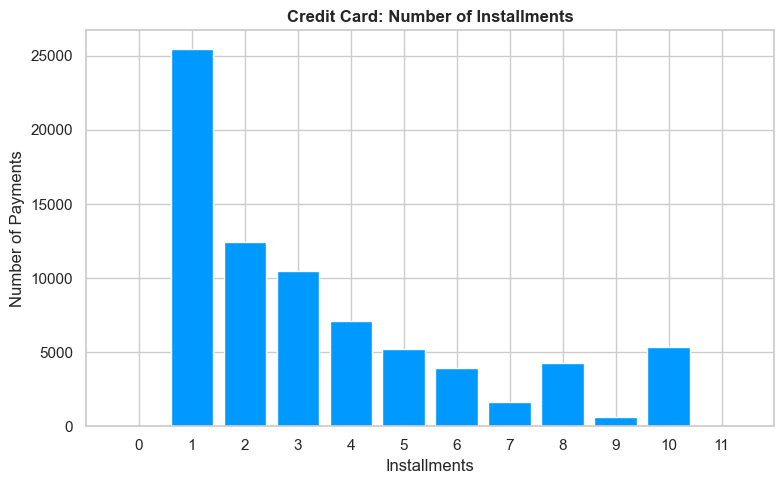

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    installments.index.astype(str),
    installments.values,
    color="#0099ff",
    edgecolor='white'
)

plt.title('Credit Card: Number of Installments',fontsize=12, fontweight='bold')
plt.xlabel('Installments')
plt.ylabel('Number of Payments')

plt.tight_layout()
plt.show()

**Interpretation:**  
**Credit card** dominates Brazilian e-commerce, accounting for roughly 74% of all payments and growing consistently over the dataset period. **Boleto bancário** (a Brazilian bank slip payment method common among unbanked consumers) is the second most popular method at ~19%, highlighting that a significant portion of the customer base lacks credit cards — a key financial inclusion concern.

Among credit card users, **single-installment payments (1x)** are most common, but a notable share pay in 10 installments, reflecting Brazil's widespread installment payment culture ("parcelamento").

**SDG 8 implication:** The prevalence of Boleto payments shows that e-commerce is reaching financially excluded populations. Improving digital payment infrastructure and expanding debit/Pix options could further democratize access to the digital economy.



## Limitations

- The dataset covers **2016–2018 only**, trends may not reflect Brazil's current e-commerce landscape, which grew sharply during the 2020 pandemic.
- Repeat buyer analysis is limited by the dataset window. A customer who bought once in 2018 may have returned in 2019, but that would not appear here.
- Geographic analysis is at **state level**. City-level patterns, especially within large states like SP and MG, are not visible.
- The dataset does not include seller-side data (seller revenue, churn) which would be needed to make stronger SDG 8 claims about decent work and employment.


## Conclusion

Brazil's e-commerce ecosystem shows strong growth momentum that aligns with SDG 8 goals. However, two structural problems limit its potential as an engine of inclusive economic growth: **logistics inequality between regions** and **low customer retention**. Addressing last-mile delivery in the Northeast and investing in retention tools for sellers in recurring-need categories are the two highest-impact interventions suggested by this analysis.

In [43]:
# Cleaned Dataset Export
# One dataframe our analysis actually used : the merged, cleaned version. 
cleaned = orders[orders['order_status'] == 'delivered'].copy()

cleaned['order_purchase_timestamp']      = pd.to_datetime(cleaned['order_purchase_timestamp'])
cleaned['order_delivered_customer_date'] = pd.to_datetime(cleaned['order_delivered_customer_date'])
cleaned['order_estimated_delivery_date'] = pd.to_datetime(cleaned['order_estimated_delivery_date'])

cleaned['delivery_delay'] = (cleaned['order_delivered_customer_date'] - cleaned['order_estimated_delivery_date']).dt.days
cleaned['is_late']    = (cleaned['delivery_delay'] > 0).astype(int)
cleaned['year_month'] = cleaned['order_purchase_timestamp'].dt.to_period('M').astype(str)

cleaned = cleaned.merge(customer[['customer_id', 'customer_unique_id', 'customer_state']],on='customer_id', how='left')
cleaned = cleaned.merge(order_reviews[['order_id', 'review_score']].drop_duplicates('order_id'),on='order_id', how='left')
pay_summary = order_payments.groupby('order_id').agg(
    payment_type=('payment_type', 'first'),
    payment_value=('payment_value', 'sum')
).reset_index()
cleaned = cleaned.merge(pay_summary, on='order_id', how='left')

cleaned = cleaned.dropna(subset=['delivery_delay', 'review_score'])

print(f'Cleaned dataset shape: {cleaned.shape}')
print(f'Columns: {cleaned.columns.tolist()}')
cleaned.to_csv('../data/processed/cleaned_dataset.csv', index=False)
print('Saved: data/processed/cleaned_dataset.csv')

Cleaned dataset shape: (95824, 16)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_delay', 'is_late', 'year_month', 'customer_unique_id', 'customer_state', 'review_score', 'payment_type', 'payment_value']
Saved: cleaned_dataset.csv
